In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc

from imblearn.over_sampling import SMOTE

In [2]:
df = pd.read_csv("diabetes.csv")

print(df.head())
print(df.info())
print(df.describe())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148           72.0             35    169.5  33.6   
1            1       85           66.0             29    102.5  26.6   
2            8      183           64.0             32    169.5  23.3   
3            1       89           66.0             23     94.0  28.1   
4            0      137           40.0             35    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768

In [3]:
# Replace 0 values (invalid in some columns)
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

for col in cols:
    df[col] = df[col].replace(0, df[col].median())

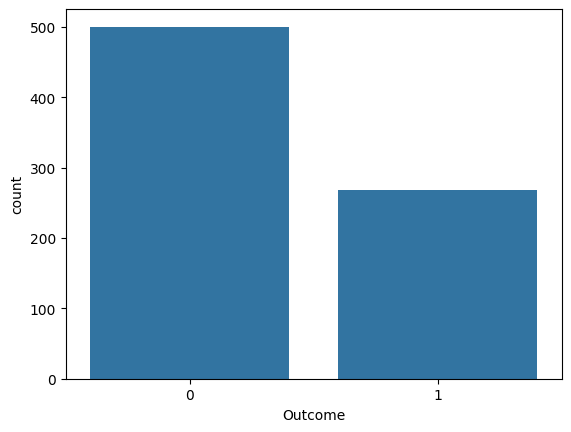

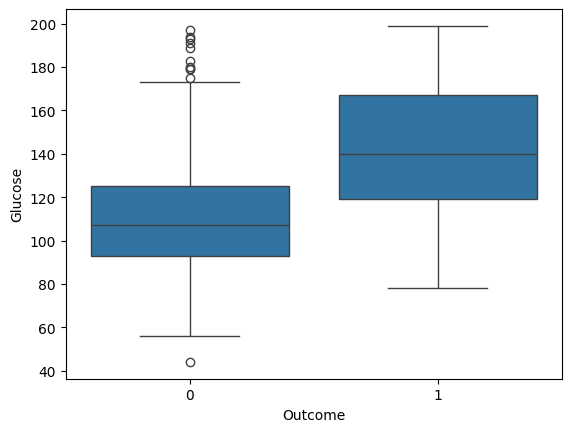

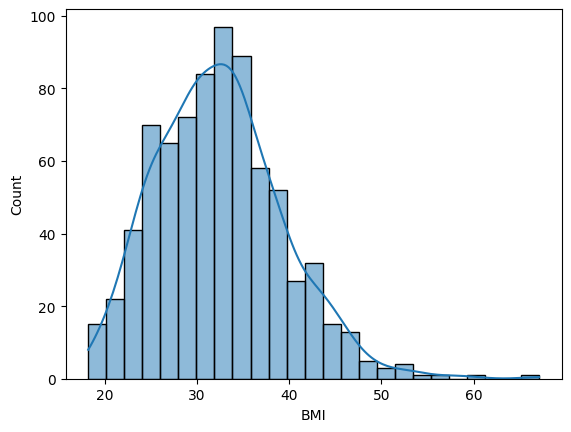

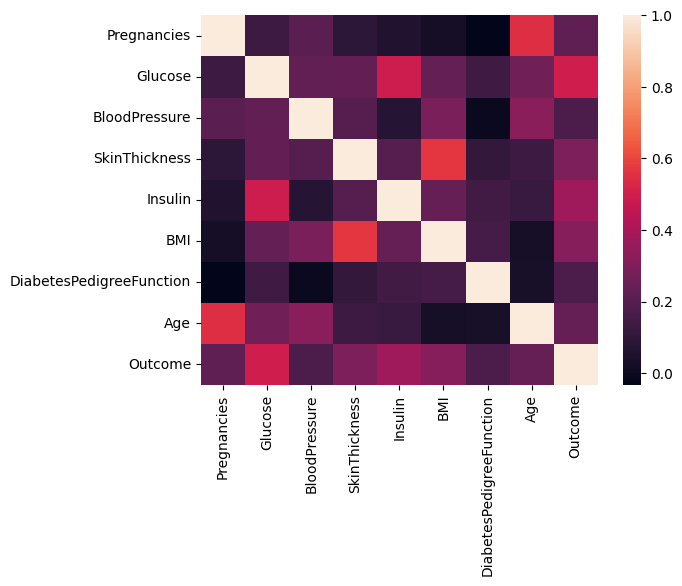

In [4]:
sns.countplot(x='Outcome', data=df)
plt.show()

sns.boxplot(x='Outcome', y='Glucose', data=df)
plt.show()

sns.histplot(df['BMI'], kde=True)
plt.show()

sns.heatmap(df.corr(), annot=False)
plt.show()

In [5]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [6]:
print("Before:", np.bincount(y_train))

sm = SMOTE()
X_train, y_train = sm.fit_resample(X_train, y_train)

print("After:", np.bincount(y_train))

Before: [400 214]
After: [400 400]


In [7]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("LR Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

LR Accuracy: 0.7987012987012987
              precision    recall  f1-score   support

           0       0.87      0.81      0.84       100
           1       0.69      0.78      0.73        54

    accuracy                           0.80       154
   macro avg       0.78      0.79      0.78       154
weighted avg       0.81      0.80      0.80       154



In [8]:
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 0.8896103896103896
              precision    recall  f1-score   support

           0       0.95      0.88      0.91       100
           1       0.80      0.91      0.85        54

    accuracy                           0.89       154
   macro avg       0.87      0.89      0.88       154
weighted avg       0.90      0.89      0.89       154



In [9]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print("DT Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

DT Accuracy: 0.8441558441558441
              precision    recall  f1-score   support

           0       0.87      0.89      0.88       100
           1       0.79      0.76      0.77        54

    accuracy                           0.84       154
   macro avg       0.83      0.82      0.83       154
weighted avg       0.84      0.84      0.84       154



In [10]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("RF Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

RF Accuracy: 0.9090909090909091
              precision    recall  f1-score   support

           0       0.94      0.92      0.93       100
           1       0.86      0.89      0.87        54

    accuracy                           0.91       154
   macro avg       0.90      0.90      0.90       154
weighted avg       0.91      0.91      0.91       154



In [11]:
ada = AdaBoostClassifier()
ada.fit(X_train, y_train)
y_pred_ada = ada.predict(X_test)

print("ADA Accuracy:", accuracy_score(y_test, y_pred_ada))
print(classification_report(y_test, y_pred_ada))

ADA Accuracy: 0.922077922077922
              precision    recall  f1-score   support

           0       0.96      0.92      0.94       100
           1       0.86      0.93      0.89        54

    accuracy                           0.92       154
   macro avg       0.91      0.92      0.92       154
weighted avg       0.92      0.92      0.92       154



In [12]:
gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)

print("GB Accuracy:", accuracy_score(y_test, y_pred_gb))
print(classification_report(y_test, y_pred_gb))

GB Accuracy: 0.9285714285714286
              precision    recall  f1-score   support

           0       0.95      0.94      0.94       100
           1       0.89      0.91      0.90        54

    accuracy                           0.93       154
   macro avg       0.92      0.92      0.92       154
weighted avg       0.93      0.93      0.93       154



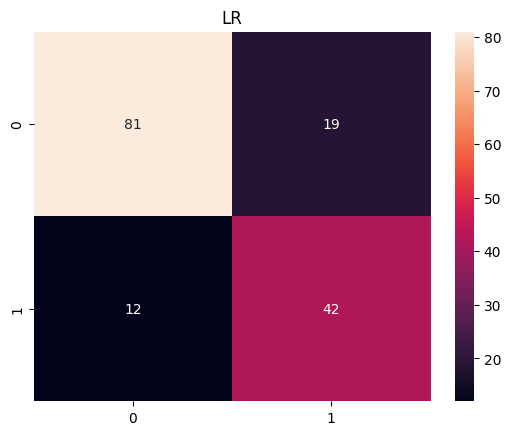

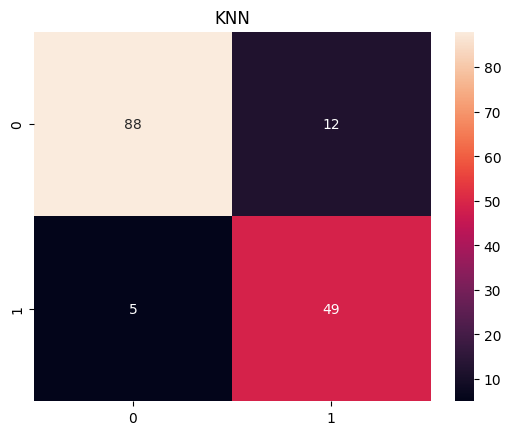

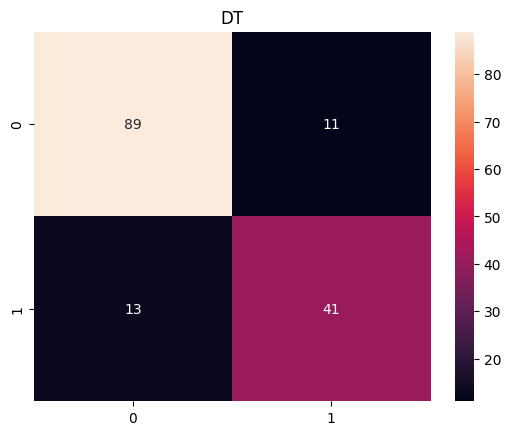

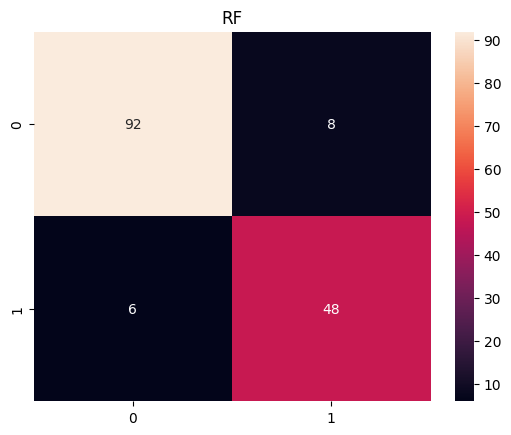

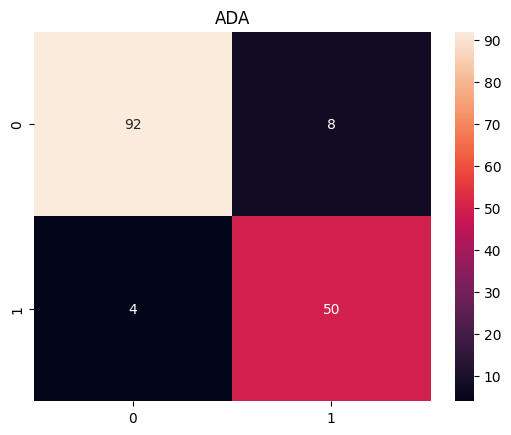

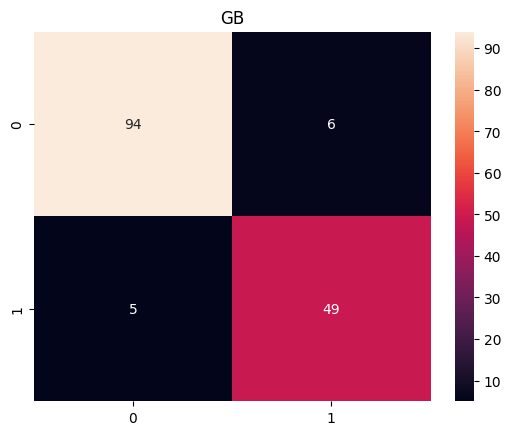

In [13]:
models = {
    "LR": y_pred_lr,
    "KNN": y_pred_knn,
    "DT": y_pred_dt,
    "RF": y_pred_rf,
    "ADA": y_pred_ada,
    "GB": y_pred_gb
}

for name, preds in models.items():
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d')
    plt.title(name)
    plt.show()

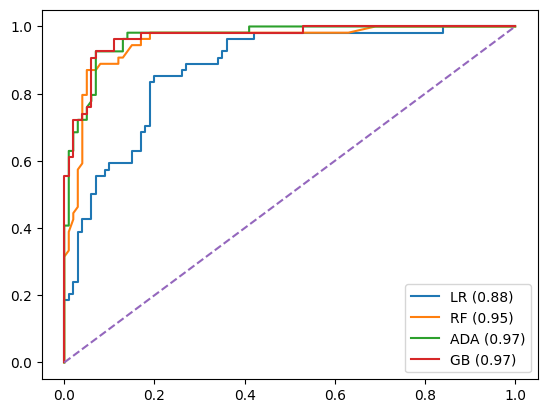

In [14]:
plt.figure()

for model, clf in [("LR", lr), ("RF", rf), ("ADA", ada), ("GB", gb)]:
    y_prob = clf.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{model} ({roc_auc:.2f})")

plt.plot([0,1],[0,1],'--')
plt.legend()
plt.show()

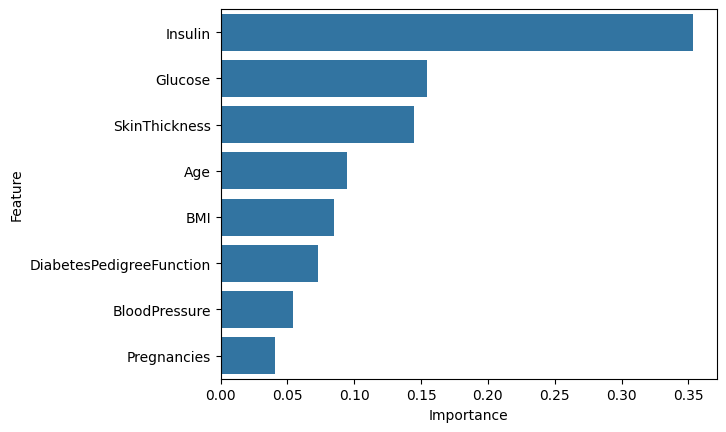

In [15]:
importances = rf.feature_importances_

feat_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

sns.barplot(x="Importance", y="Feature", data=feat_df)
plt.show()

In [16]:
print("Final Conclusion:")
print("- Glucose and BMI are major factors.")
print("- Ensemble models performed better.")
print("- SMOTE improved minority detection.")

Final Conclusion:
- Glucose and BMI are major factors.
- Ensemble models performed better.
- SMOTE improved minority detection.
